In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("train.csv")

In [3]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\r\nWhy the edits made under my use...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\r\nMore\r\nI can't make any real suggestions...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [4]:
df.shape

(159571, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


In [6]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [7]:
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

df["any_toxic"] = (df[labels].sum(axis=1) > 0).astype(int)

df[labels + ["any_toxic"]].head(10)

,toxic,severe_toxic,obscene,threat,insult,identity_hate,any_toxic
0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0
6,1,1,1,0,1,0,1
7,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0


In [9]:
print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["any_toxic"].value_counts())

print("\nTarget distribution (%):")
print((df["any_toxic"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (159571, 9)

Target distribution:
any_toxic
0    143346
1     16225
Name: count, dtype: int64

Target distribution (%):
any_toxic
0    89.83
1    10.17
Name: proportion, dtype: float64


In [10]:
df["char_count"] = df["comment_text"].str.len()
df["word_count"] = df["comment_text"].str.split().str.len()

df[["comment_text", "char_count", "word_count", "any_toxic"]].head()

,comment_text,char_count,word_count,any_toxic
0,Explanation\r\nWhy the edits made under my use...,265,43,0
1,D'aww! He matches this background colour I'm s...,112,17,0
2,"Hey man, I'm really not trying to edit war. It...",233,42,0
3,"""\r\nMore\r\nI can't make any real suggestions...",626,113,0
4,"You, sir, are my hero. Any chance you remember...",67,13,0


In [11]:
df[["char_count", "word_count"]].describe()

,char_count,word_count
count,159571.000000,159571.000000
mean,396.593961,67.273527
std,594.387869,99.230702
min,6.000000,1.000000
25%,97.000000,17.000000
50%,207.000000,36.000000
75%,438.000000,75.000000
max,5000.000000,1411.000000


In [12]:
df.groupby("any_toxic")[["char_count", "word_count"]].median()

,char_count,word_count
any_toxic,,
0,218.0,38.0
1,129.0,23.0


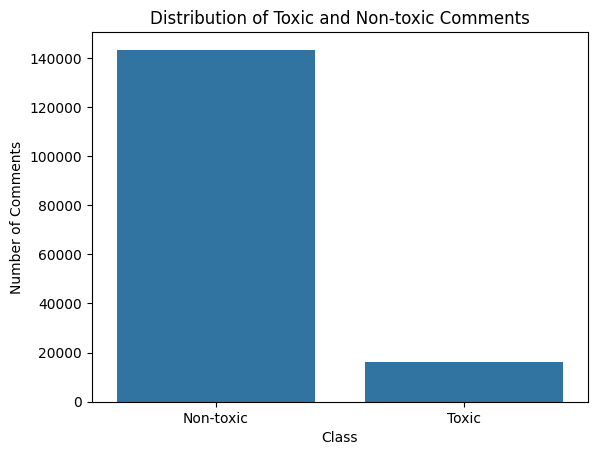

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="any_toxic")
plt.xticks([0, 1], ["Non-toxic", "Toxic"])
plt.title("Distribution of Toxic and Non-toxic Comments")
plt.xlabel("Class")
plt.ylabel("Number of Comments")
plt.show()

In [14]:
from sklearn.model_selection import train_test_split

X = df["comment_text"]
y = df["any_toxic"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

Training samples: 127656
Testing samples: 31915

Training class distribution:
any_toxic
0    89.83
1    10.17
Name: proportion, dtype: float64


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    stop_words="english",
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (127656, 30000)
Testing TF-IDF shape: (31915, 30000)


In [16]:
from sklearn.svm import LinearSVC

svc_model = LinearSVC(random_state=42)

svc_model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [17]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

y_pred = svc_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-toxic", "Toxic"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9591101362995457

Classification Report:
              precision    recall  f1-score   support

   Non-toxic       0.97      0.99      0.98     28670
       Toxic       0.87      0.70      0.78      3245

    accuracy                           0.96     31915
   macro avg       0.92      0.84      0.88     31915
weighted avg       0.96      0.96      0.96     31915


Confusion Matrix:
[[28340   330]
 [  975  2270]]


In [18]:
y_scores = svc_model.decision_function(X_test_tfidf)

print("Minimum score:", y_scores.min())
print("Maximum score:", y_scores.max())
print("First 10 scores:", y_scores[:10])

Minimum score: -3.4700241177080224
Maximum score: 12.444027788682524
First 10 scores: [-1.63020016 -1.41284557  1.02105822 -1.38918125 -1.15836621 -0.64615156
 -0.93788334 -1.98067474 -1.4675764  -1.47491077]


In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [-0.5, -0.25, 0, 0.25, 0.5]
results = []

for threshold in thresholds:
    y_pred_threshold = (y_scores >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Toxic Precision": precision_score(y_test, y_pred_threshold),
        "Toxic Recall": recall_score(y_test, y_pred_threshold),
        "Toxic F1": f1_score(y_test, y_pred_threshold)
    })

results_df = pd.DataFrame(results)
results_df.round(3)

,Threshold,Toxic Precision,Toxic Recall,Toxic F1
0,-0.50,0.668,0.838,0.744
1,-0.25,0.796,0.774,0.785
2,0.00,0.873,0.700,0.777
3,0.25,0.926,0.637,0.755
4,0.50,0.954,0.576,0.719


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    max_features=30000,
    sublinear_tf=True,
    min_df=2
)

X_train_char = char_tfidf.fit_transform(X_train)
X_test_char = char_tfidf.transform(X_test)

print("Training character features:", X_train_char.shape)
print("Testing character features:", X_test_char.shape)

Training character features: (127656, 30000)
Testing character features: (31915, 30000)


In [21]:
from scipy.sparse import hstack

X_train_combined = hstack([
    X_train_tfidf,
    X_train_char
]).tocsr()

X_test_combined = hstack([
    X_test_tfidf,
    X_test_char
]).tocsr()

print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape:", X_test_combined.shape)

Combined training shape: (127656, 60000)
Combined testing shape: (31915, 60000)


In [22]:
from sklearn.svm import LinearSVC

svc_combined = LinearSVC(random_state=42)

svc_combined.fit(X_train_combined, y_train)

print("Combined-feature model training completed!")

Combined-feature model training completed!


In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred_combined = svc_combined.predict(X_test_combined)

print("Accuracy:", accuracy_score(y_test, y_pred_combined))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_combined,
    target_names=["Non-toxic", "Toxic"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_combined))

Accuracy: 0.9621181262729124

Classification Report:
              precision    recall  f1-score   support

   Non-toxic       0.97      0.99      0.98     28670
       Toxic       0.87      0.74      0.80      3245

    accuracy                           0.96     31915
   macro avg       0.92      0.86      0.89     31915
weighted avg       0.96      0.96      0.96     31915


Confusion Matrix:
[[28301   369]
 [  840  2405]]


In [25]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV

svc = LinearSVC(random_state=42)

param_grid = {
    "C": [0.1, 1]
}

grid_search = GridSearchCV(
    estimator=svc,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=1,
    verbose=2
)

grid_search.fit(X_train_combined, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

Fitting 3 folds for each of 2 candidates, totalling 6 fits
[CV] END ..............................................C=0.1; total time=   7.6s
[CV] END ..............................................C=0.1; total time=   5.6s
[CV] END ..............................................C=0.1; total time=   5.8s
[CV] END ................................................C=1; total time=   7.1s
[CV] END ................................................C=1; total time=   8.7s
[CV] END ................................................C=1; total time=   8.2s
Best Parameters: {'C': 1}
Best CV F1-score: 0.7968844153691771


In [26]:
best_svc = grid_search.best_estimator_

print("Best model:", best_svc)

Best model: LinearSVC(C=1, random_state=42)


In [27]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred_best = best_svc.predict(X_test_combined)

print("Accuracy:", accuracy_score(y_test, y_pred_best))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=["Non-toxic", "Toxic"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

Accuracy: 0.9621181262729124

Classification Report:
              precision    recall  f1-score   support

   Non-toxic       0.97      0.99      0.98     28670
       Toxic       0.87      0.74      0.80      3245

    accuracy                           0.96     31915
   macro avg       0.92      0.86      0.89     31915
weighted avg       0.96      0.96      0.96     31915


Confusion Matrix:
[[28301   369]
 [  840  2405]]


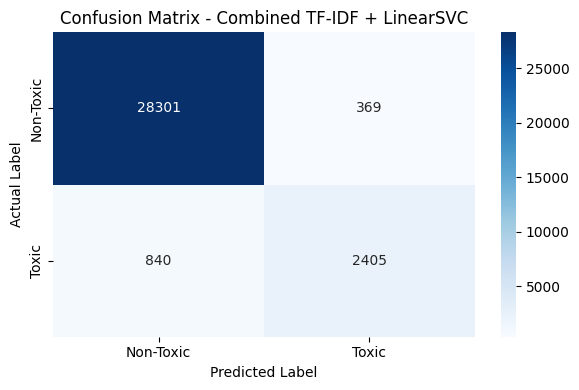

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = best_svc.predict(X_test_combined)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Toxic", "Toxic"],
    yticklabels=["Non-Toxic", "Toxic"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Combined TF-IDF + LinearSVC")
plt.tight_layout()
plt.show()

In [30]:
import os
import joblib

os.makedirs("jigsaw", exist_ok=True)

joblib.dump(best_svc, "jigsaw/toxic_svc_model.pkl")
joblib.dump(tfidf, "jigsaw/word_tfidf.pkl")
joblib.dump(char_tfidf, "jigsaw/char_tfidf.pkl")

print("Model and vectorizers saved successfully!")

Model and vectorizers saved successfully!


In [34]:
import joblib

loaded_model = joblib.load("toxic_svc_model.pkl")
loaded_word_tfidf = joblib.load("word_tfidf.pkl")
loaded_char_tfidf = joblib.load("char_tfidf.pkl")

print("Model:", type(loaded_model).__name__)
print("Word vectorizer:", type(loaded_word_tfidf).__name__)
print("Character vectorizer:", type(loaded_char_tfidf).__name__)

Model: LinearSVC
Word vectorizer: TfidfVectorizer
Character vectorizer: TfidfVectorizer


In [35]:
from scipy.sparse import hstack

test_comments = [
    "Thank you for sharing this helpful information.",
    "You are an idiot and nobody wants you here."
]

word_features = loaded_word_tfidf.transform(test_comments)
char_features = loaded_char_tfidf.transform(test_comments)

combined_features = hstack(
    [word_features, char_features]
).tocsr()

predictions = loaded_model.predict(combined_features)

for comment, prediction in zip(test_comments, predictions):
    label = "Toxic" if prediction == 1 else "Non-Toxic"
    print(f"Comment: {comment}")
    print(f"Prediction: {label}\n")

Comment: Thank you for sharing this helpful information.
Prediction: Non-Toxic

Comment: You are an idiot and nobody wants you here.
Prediction: Toxic

